## Global Wheat Detection

In project you will use the [PlantVillage Dataset](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset) to develop a deep learning model plant disease classification

You can also do the same with a custom dataset. Just make sure you inform your instructor.

Ensure that the selected dataset is appropriately preprocessed and split into training, validation, and testing sets. Augmentation techniques such as image rotations, flips, and brightness adjustments can be applied to increase the dataset’s diversity and improve model generalization.

### Problem Statement
Develop a deep learning model for wheat detection and disease classification to aid farmers in improving crop management and yield.  The final goal is to create a reliable and efficient system that can assist farmers in making informed decisions regarding crop protection and overall agricultural practices.

Remember to provide detailed documentation, including an explanation of the deep learning techniques used, model architecture, training methodology, and deployment instructions where applicable.


## PLANT DATASET

In [7]:
import os, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Your path (raw string so the backslashes are safe on Windows)
DATA_ROOT = Path(r"C:\Users\Admin\plant\Plant village dataset\plantvillage dataset")

IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
print("TF:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TF: 2.22.0-rc0 | GPUs: []


In [8]:
# check folders
print("Exists:", DATA_ROOT.exists())
for p in sorted(DATA_ROOT.iterdir()):
    print(" -", p.name, "(dir)" if p.is_dir() else "")

Exists: True
 - color (dir)
 - grayscale (dir)
 - segmented (dir)


In [9]:
# Find the folder named "color" anywhere under DATA_ROOT
color_candidates = [p for p in DATA_ROOT.rglob("*") if p.is_dir() and p.name.lower() == "color"]
assert color_candidates, f"No 'color' folder found under {DATA_ROOT}. Check the path printed above."
color_dir = color_candidates[0]
print("Using:", color_dir)

# Collect images (single pass, case-insensitive, so no duplicates)
valid_ext = {".jpg", ".jpeg", ".png"}
files = [p for p in color_dir.rglob("*") if p.is_file() and p.suffix.lower() in valid_ext]
assert len(files) > 0, "No images found. Check the folder structure."

df = pd.DataFrame({"filepath": [str(p) for p in files]})
df["label"] = [p.parent.name for p in files]
df["plant"] = df.label.str.split("___").str[0]
df["state"] = df.label.str.split("___").str[1]
df["healthy"] = df.state.str.lower().eq("healthy")
df = df.drop_duplicates(subset="filepath").reset_index(drop=True)

print("Images:", len(df), "| Classes:", df.label.nunique(), "| Plants:", df.plant.nunique())
print(df.healthy.value_counts())

Using: C:\Users\Admin\plant\Plant village dataset\plantvillage dataset\color
Images: 54305 | Classes: 38 | Plants: 14
healthy
False    39221
True     15084
Name: count, dtype: int64


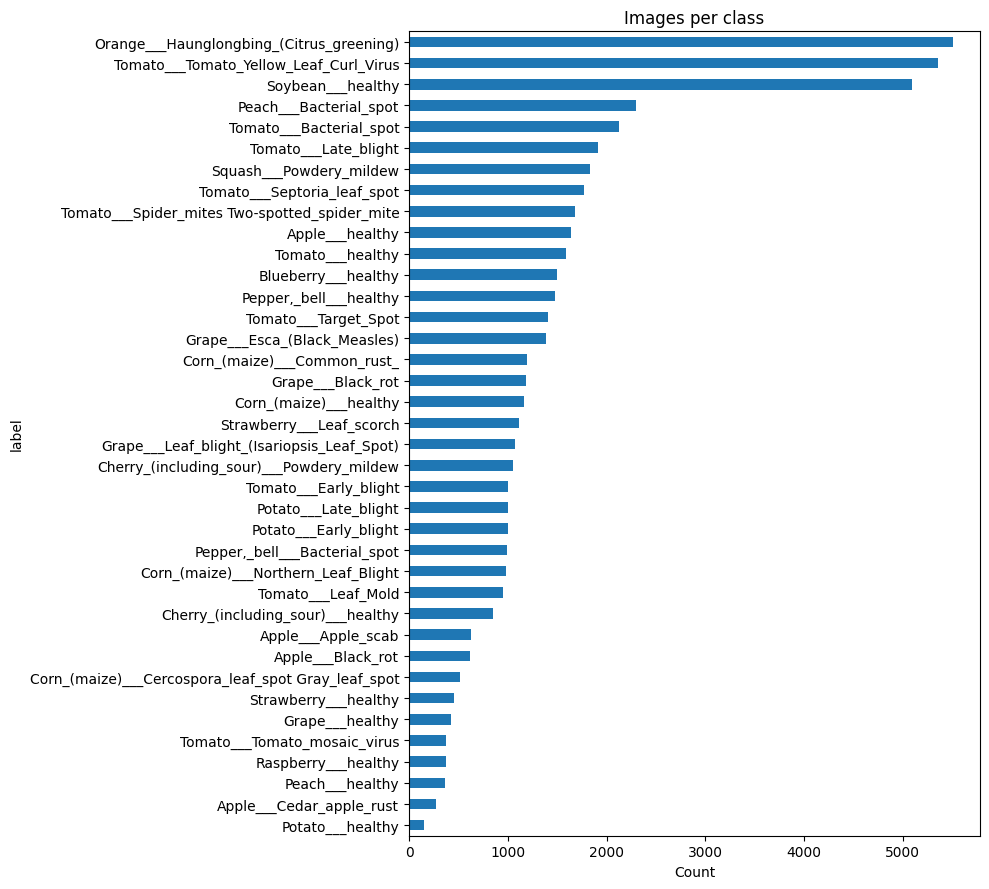

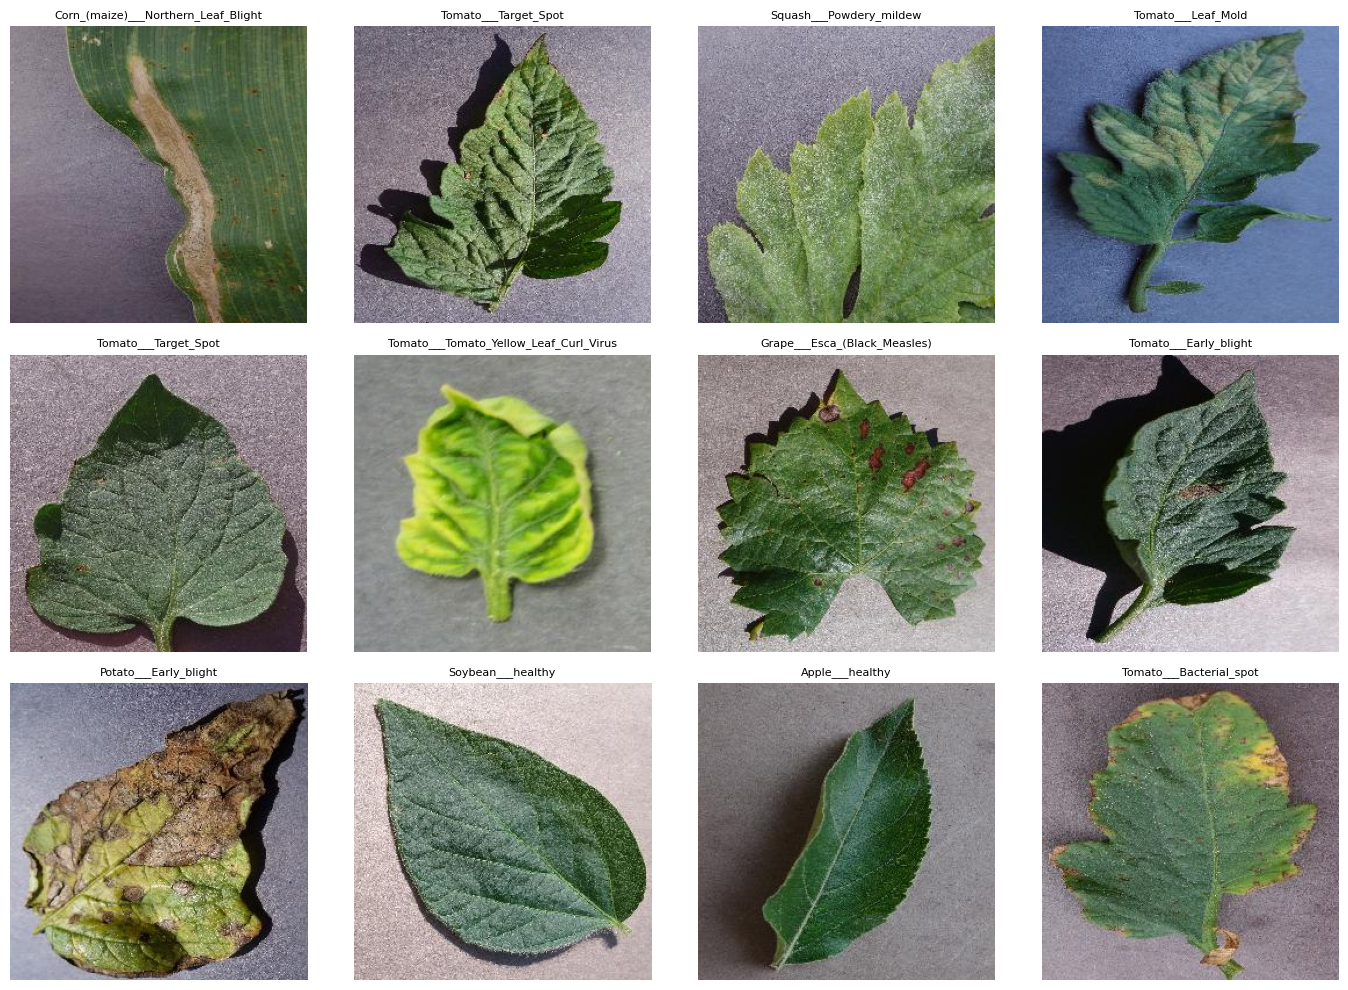

In [10]:
# plots
plt.figure(figsize=(10, 9))
df.label.value_counts().sort_values().plot(kind="barh")
plt.title("Images per class"); plt.xlabel("Count"); plt.tight_layout(); plt.show()

n = min(12, len(df))
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, (_, row) in zip(axes.ravel(), df.sample(n, random_state=SEED).iterrows()):
    ax.imshow(plt.imread(row.filepath)); ax.set_title(row.label, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [11]:
# training/validation split
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)

print(len(train_df), len(val_df), len(test_df))

class_names = sorted(df.label.unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
NUM_CLASSES = len(class_names)

38013 8146 8146


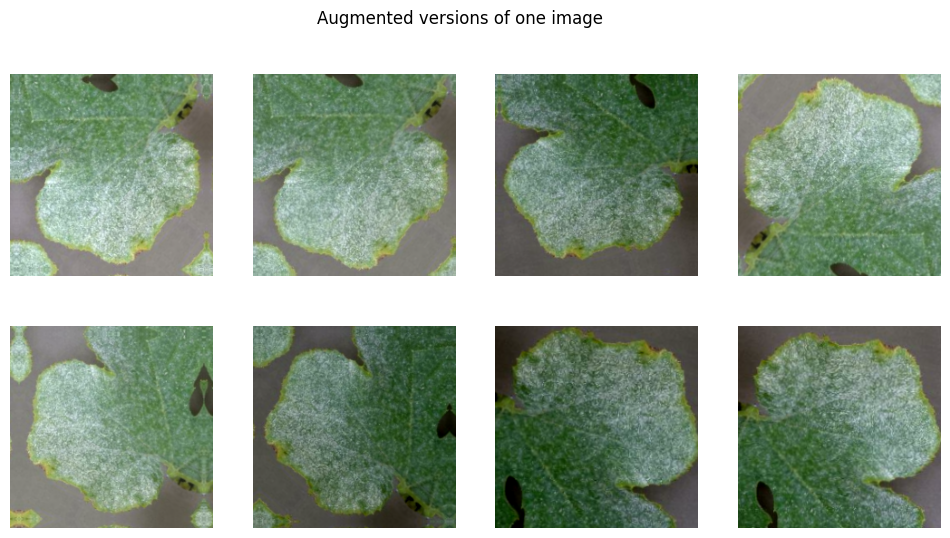

In [12]:
# data pipeline with augmentation
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)          # 256x256 -> 224x224
    return img, label

def make_ds(frame, training=False):
    paths = frame.filepath.values
    labels = frame.label.map(class_to_idx).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)       # not shuffled, so label order is preserved

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),                              # about ±54°
    layers.RandomZoom(0.10),
    layers.RandomBrightness(0.20, value_range=(0, 255)),
    layers.RandomContrast(0.20),
], name="augmentation")

# Preview augmentation
imgs, _ = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(augment(imgs[:1], training=True)[0].numpy().astype("uint8"))
    plt.axis("off")
plt.suptitle("Augmented versions of one image"); plt.show()

In [14]:
# build the model(mobileNetV2)
base = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base.trainable = False   # freeze for phase 1

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,686 (9.90 MB)

 Trainable params: 337,702 (1.29 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
# model fit
# train in 2 phases 
callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor="val_loss"),
    keras.callbacks.ReduceLROnPlateau(factor=0.3, patience=2, monitor="val_loss"),
    keras.callbacks.ModelCheckpoint("best_model.keras", save_best_only=True, monitor="val_loss"),
]

# Phase 1: train only the new classification head
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)

# Phase 2: fine-tune the top of the backbone at a low learning rate
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

hist2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

# Training curves
acc  = hist1.history["accuracy"] + hist2.history["accuracy"]
vacc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
loss = hist1.history["loss"] + hist2.history["loss"]
vloss = hist1.history["val_loss"] + hist2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="val"); ax[1].set_title("Loss"); ax[1].legend()
for a in ax: a.axvline(len(hist1.history["loss"]) - 0.5, ls="--", c="gray")
plt.show()

Epoch 1/8


c:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1791s 1s/step - accuracy: 0.8627 - loss: 0.4576 - val_accuracy: 0.9030 - val_loss: 0.2867 - learning_rate: 0.0010
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1792s 2s/step - accuracy: 0.9203 - loss: 0.2392 - val_accuracy: 0.9254 - val_loss: 0.2293 - learning_rate: 0.0010
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1731s 1s/step - accuracy: 0.9304 - loss: 0.2063 - val_accuracy: 0.9179 - val_loss: 0.2381 - learning_rate: 0.0010
Epoch 4/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1439s 1s/step - accuracy: 0.9355 - loss: 0.1853 - val_accuracy: 0.9325 - val_loss: 0.1996 - learning_rate: 0.0010
Epoch 5/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1430s 1s/step - accuracy: 0.9400 - loss: 0.1751 - val_accuracy: 0.9330 - val_loss: 0.2030 - learning_rate: 0.0010
Epoch 6/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1471s 1s/step - accuracy: 0.9437 - loss: 0.1635 - val_accuracy: 0.9351 - val_loss: 0.1878 - learning_rate: 0.0010
Epoch 7/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 1398s 1s/step - accuracy: 0.9471 - loss

KeyboardInterrupt: 

In [ ]:
# evaluate the untouched set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_true = test_df.label.map(class_to_idx).values
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6); plt.tight_layout(); plt.show()

# Show some mistakes
wrong = np.where(y_pred != y_true)[0][:8]
plt.figure(figsize=(14, 6))
for i, idx in enumerate(wrong):
    plt.subplot(2, 4, i + 1)
    plt.imshow(plt.imread(test_df.filepath.iloc[idx]))
    plt.title(f"T: {class_names[y_true[idx]][:22]}\nP: {class_names[y_pred[idx]][:22]}", fontsize=7)
    plt.axis("off")
plt.show()

194/255 ━━━━━━━━━━━━━━━━━━━━ 1:07 1s/step - accuracy: 0.9422 - loss: 0.1790

In [ ]:
# save the model
model.save("plant_disease_model.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

def predict_image(path, top_k=3):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, IMG_SIZE)[None]
    probs = model.predict(img, verbose=0)[0]
    top = probs.argsort()[::-1][:top_k]
    return [(class_names[i], float(probs[i])) for i in top]

print(predict_image(test_df.filepath.iloc[0]))